# Formative 3: Probability Distributions, Bayesian Probability and Gradient Descent
### Group: 11

| Member | Part led |
|---|---|
| Milliam Mukamukiza | Part 1 (EM algorithm) |
| Dedine Mukabucyana | Part 2 (Bayesian probability) |
| Cedric Bigwi Hindura | Parts 3 & 4 (Gradient descent) |

*Mathematics for Machine Learning, African Leadership University. All three members present every part. Algorithms live in `src/` (`em.py`, `bayes.py`, `gradient_descent.py`) and are imported here, so the notebook shows results and reasoning without duplicating code.*

To run: `pip install -r requirements.txt`, place `IMDB Dataset.csv` in `data/` (see `data/README.md`), then Restart and Run All.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import em, bayes
from src import gradient_descent as gd
from src import plotting as pl
from src.data import load_galton

pl.use_plain_style()
pd.options.display.float_format = "{:.4f}".format

GALTON_CSV = "data/GaltonFamilies.csv"
IMDB_CSV = "data/IMDB Dataset.csv"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)

---
# Part 1: Probability distributions and the EM algorithm

**Question.** Heights of two populations are pooled and the labels are deleted. Can a model discover the two groups on its own?

**Data.** Galton family heights. We compare **mothers and children** (one mother per family, every child). Set `PARENT = "father"` below to repeat the analysis with fathers. The labels are kept aside and used only to grade the result at the end.

In [2]:
PARENT = "mother"          # "mother" or "father"
heights, labels, subgroup = load_galton(GALTON_CSV, PARENT)
print(f"{(labels == 0).sum()} {PARENT}s + {(labels == 1).sum()} children = {len(heights)} pooled heights")

205 mothers + 934 children = 1139 pooled heights


### How EM works

The model is a weighted sum of two Gaussians:

$$p(x)=\pi_1\,\mathcal N(x\mid\mu_1,\sigma_1^2)+\pi_2\,\mathcal N(x\mid\mu_2,\sigma_2^2)$$

**1. Initialize.** Put the means at the 25th and 75th percentiles, give both variances the value of the data variance, and set $\pi_1=\pi_2=0.5$.

**2. E-step.** Give every height a *responsibility*: the probability that it came from each component, using the current parameters.

$$r_{ik}=\frac{\pi_k\,\mathcal N(x_i\mid\mu_k,\sigma_k^2)}{\pi_1\,\mathcal N(x_i\mid\mu_1,\sigma_1^2)+\pi_2\,\mathcal N(x_i\mid\mu_2,\sigma_2^2)}$$

**3. M-step.** Re-estimate each component, weighting every height by its responsibility. Let $N_k=\sum_i r_{ik}$ be the effective number of heights in component $k$.

$$\mu_k=\frac{\sum_i r_{ik}\,x_i}{N_k}\qquad\qquad
\sigma_k^2=\frac{\sum_i r_{ik}\,(x_i-\mu_k)^2}{N_k}\qquad\qquad
\pi_k=\frac{N_k}{N}$$

**4. Repeat and stop.** Alternate steps 2 and 3 until the log-likelihood barely changes:

$$\left|\ln L_t-\ln L_{t-1}\right|<10^{-6}$$

Implemented in `src/em.py`: `initialize`, `e_step`, `m_step`, `fit`.

### Run EM and show the required tracking table

In [3]:
history = em.fit(heights)
final, final_ll = history[-1]
print(f"Stopped after {len(history) - 1} iterations, final log-likelihood {final_ll:.4f}\n")
em.tracking_table(history, n_iterations=2).style.hide(axis="index").format("{:.4f}", subset=pd.IndexSlice[:, "mu1":])

Stopped after 386 iterations, final log-likelihood -3035.7484



Iteration,mu1,mu2,sigma1^2,sigma2^2,pi1,pi2,Log-likelihood
0,63.5000,69.0000,12.5802,12.5802,0.5000,0.5000,-3115.4014
1,64.3037,68.2536,7.5712,9.8201,0.5067,0.4933,-3046.1412
2,64.2587,68.3165,6.9517,10.0323,0.5087,0.4913,-3044.0230


Component 1 is the lower-mean component and component 2 the higher-mean one. EM does not know which one a person would call mothers or children.

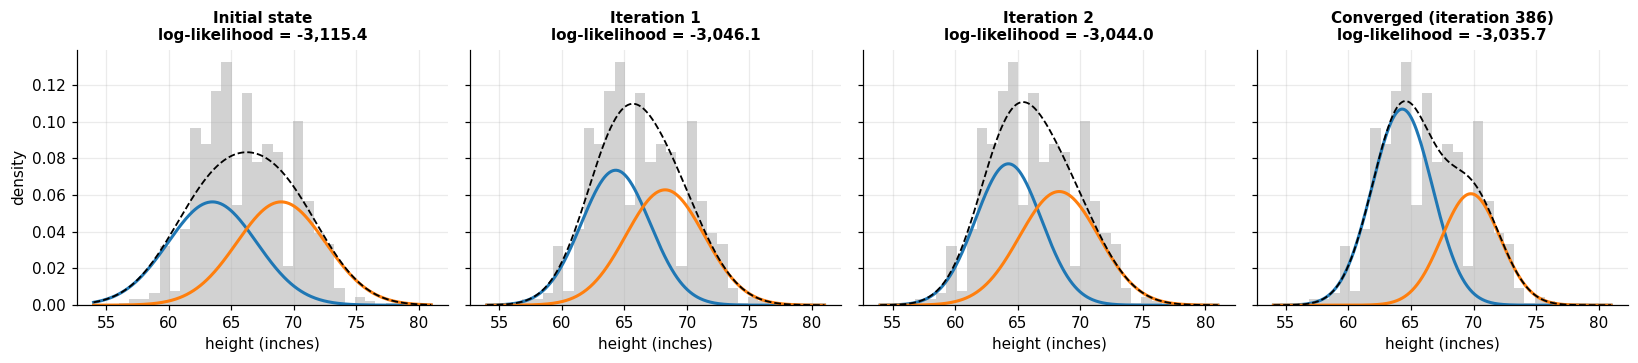

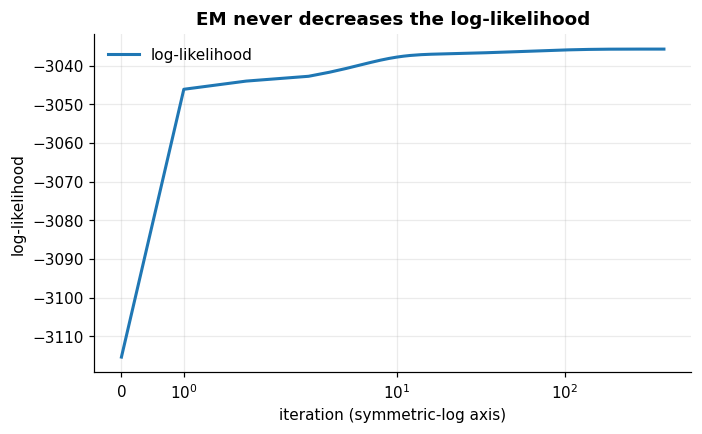

In [4]:
pl.plot_em_snapshots(heights, history, path=f"{FIG}/em_snapshots.png"); plt.show()
pl.plot_loglik(history, path=f"{FIG}/em_loglik.png"); plt.show()

**Stopping rule.** The log-likelihood never decreases. It rises quickly in the first iterations and then flattens, so we stop when an iteration improves it by less than $10^{-6}$.

### Final fitted mixture

means      : [64.2993 69.7856]
variances  : [5.7935 5.4747]
proportions: [0.6441 0.3559]


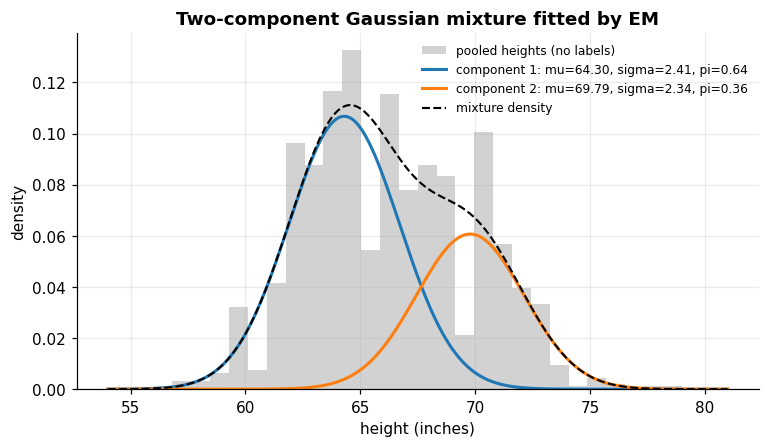

In [5]:
print("means      :", final.means.round(4))
print("variances  :", final.variances.round(4))
print("proportions:", final.proportions.round(4))
pl.plot_mixture_fit(heights, final, "Two-component Gaussian mixture fitted by EM", path=f"{FIG}/em_fit.png"); plt.show()

### Should we simply cut at the global mean and average each pile?

**No.** Three reasons, shown below with the same data:

1. **Overlap.** A hard line labels everyone on the wrong side as wrong and cannot say "about 50/50". EM returns a probability for every height.
2. **Truncation.** Cutting at a point removes the tail of each group, so each pile's variance is too small and its mean is biased toward the cut.
3. **Forced sizes.** A cut at the mean forces two roughly equal piles. EM learns the means, variances and mixing proportions together by maximizing the likelihood.

,global-mean split,EM
mean 1,63.5759,64.2993
mean 2,69.4718,69.7856
variance 1,3.4783,5.7935
variance 2,4.5477,5.4747
proportion 1,0.5461,0.6441
log-likelihood,-3061.6755,-3035.7484


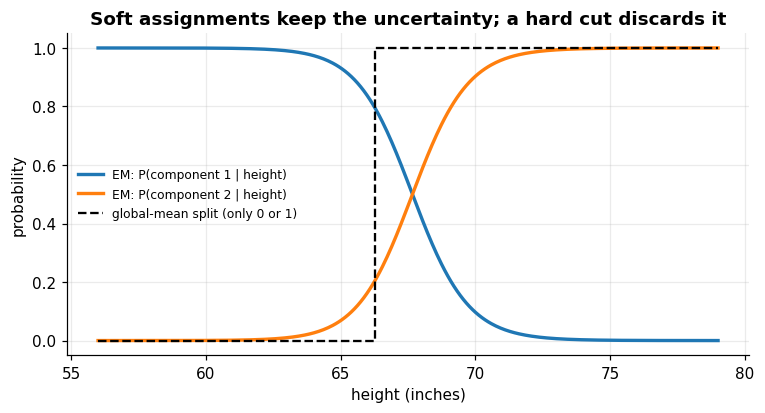

In [6]:
cut, split = em.global_mean_split(heights)
comparison = pd.DataFrame({
    "global-mean split": [*split.means, *split.variances, split.proportions[0], em.log_likelihood(heights, split)],
    "EM":                [*final.means, *final.variances, final.proportions[0], final_ll]},
    index=["mean 1", "mean 2", "variance 1", "variance 2", "proportion 1", "log-likelihood"])
display(comparison)
pl.plot_soft_vs_hard(heights, final, cut, path=f"{FIG}/soft_vs_hard.png"); plt.show()

### What did EM actually find?

If the two components were "parents" and "children", each sub-group would fall in one component. The table shows the average responsibility of component 2 (the taller one) for each sub-group.

In [7]:
r = em.e_step(heights, final)
by_group = (pd.DataFrame({"group": subgroup, "height": heights, "P(component 2)": r[:, 1]})
            .groupby("group").agg(count=("height", "size"), mean_height=("height", "mean"),
                                  mean_P_component2=("P(component 2)", "mean")))
display(by_group)

,count,mean_height,mean_P_component2
group,,,
daughter,453,64.1040,0.1152
mother,205,64.0020,0.1030
son,481,69.2341,0.6904


EM separates **shorter from taller people**, which here mostly means **female from male**: the parent group and the daughters sit in the lower component and the sons in the upper one. EM is a density model, so it finds the dominant structure in the heights, not the label a human would choose. This explains the modest classification accuracy below.

Component 1 is treated as the mother group (its mean is closest to the mothers' mean).
Accuracy 51.27%   balanced accuracy 68.39%   always-guess-child baseline 82.00%


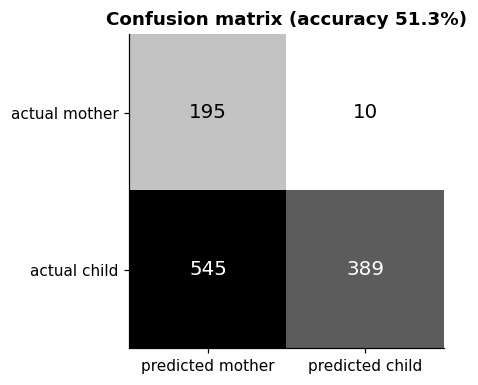

In [8]:
parent_component = em.closest_component(final, heights[labels == 0])   # component nearest the labelled parents' mean
scores = em.evaluate(heights, labels, final, parent_component)
print(f"Component {parent_component + 1} is treated as the {PARENT} group (its mean is closest to the {PARENT}s' mean).")
print(f"Accuracy {scores['accuracy']:.2%}   balanced accuracy {scores['balanced_accuracy']:.2%}   "
      f"always-guess-child baseline {scores['majority_baseline']:.2%}")
pl.plot_confusion(scores["confusion"], [PARENT, "child"], scores["accuracy"], path=f"{FIG}/em_confusion.png"); plt.show()

The evaluation reuses the data EM was fitted on, and accuracy is below the trivial baseline because 82% of the observations are children. We report this openly: the model is a valid mixture fit, but height alone barely identifies the label.

### Classify a test height

Run every cell above once so the model is fitted. Then type the height given by the coach into `TEST_HEIGHT` and re-run **only this cell**: it prints the exact posterior probability of each group.

Test height: 68.0 in
  Probability it is a child    : 0.5808   (58.1%)
  Probability it is a mother   : 0.4192   (41.9%)
  The two add up to 1.0000  ->  classified as: child


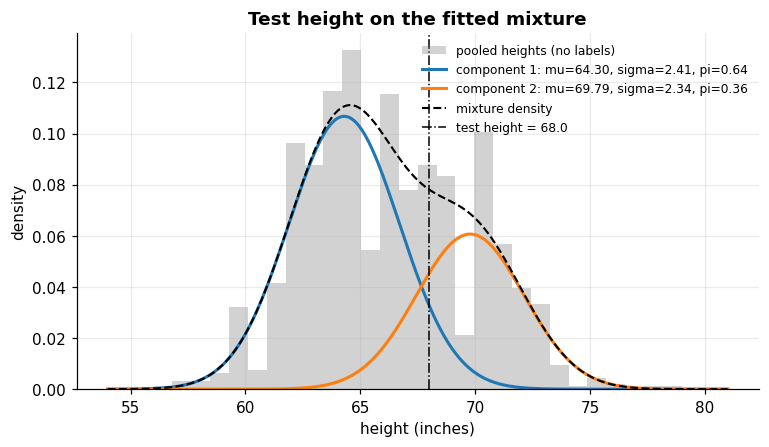

In [9]:
TEST_HEIGHT = 68.0
p_parent, p_child = em.classify(TEST_HEIGHT, final, parent_component)
print(f"Test height: {TEST_HEIGHT} in")
print(f"  Probability it is a child    : {p_child:.4f}   ({p_child:.1%})")
print(f"  Probability it is a {PARENT:<9}: {p_parent:.4f}   ({p_parent:.1%})")
print(f"  The two add up to {p_parent + p_child:.4f}  ->  classified as: {PARENT if p_parent > p_child else 'child'}")
pl.plot_mixture_fit(heights, final, "Test height on the fitted mixture", test_height=TEST_HEIGHT); plt.show()

---
# Part 2: Bayesian probability on IMDb reviews

**Choice.** We compute $P(\text{Positive}\mid\text{keyword})$ only, not $P(\text{Negative}\mid\text{keyword})$.

**Data.** 50,000 IMDb reviews, half positive and half negative, so the prior is $P(\text{Positive})=0.5$.

**Method.** Basic Python only (`csv`, `re`, sets and counting). Each review is reduced to the set of words it contains.

| Quantity | Definition |
|---|---|
| Prior $P(\text{Positive})$ | positive reviews / all reviews |
| Likelihood $P(w\mid\text{Positive})$ | positive reviews containing $w$ / positive reviews |
| Marginal $P(w)$ | reviews containing $w$ / all reviews |
| Posterior $P(\text{Positive}\mid w)$ | likelihood $\times$ prior / marginal |

$$P(\text{Positive}\mid w)=\frac{P(w\mid\text{Positive})\,P(\text{Positive})}{P(w)}$$

**Keywords and why.**

- Positive: *excellent*, *wonderful*, *amazing* (direct praise) and *great* (very common, so it tests whether a popular word is also a reliable one).
- Negative: *terrible*, *awful* (direct criticism), *boring* (a common reason for a bad review) and *worst* (used in extreme complaints).

In [10]:
POSITIVE = ["excellent", "wonderful", "amazing", "great"]
NEGATIVE = ["terrible", "awful", "boring", "worst"]
KEYWORDS = POSITIVE + NEGATIVE

reviews = bayes.load_reviews(IMDB_CSV)
print(len(reviews), "reviews loaded")
rows = bayes.bayes_table(reviews, KEYWORDS)
print(bayes.format_table(rows))

50000 reviews loaded
keyword       prior  likelihood  marginal  posterior
excellent    0.5000      0.1146    0.0710     0.8073
wonderful    0.5000      0.0902    0.0555     0.8120
amazing      0.5000      0.0671    0.0431     0.7783
great        0.5000      0.3387    0.2512     0.6741
terrible     0.5000      0.0152    0.0539     0.1413
awful        0.5000      0.0112    0.0575     0.0977
boring       0.5000      0.0236    0.0610     0.1938
worst        0.5000      0.0164    0.0886     0.0924


Worked example for one keyword, with the arithmetic written out:

In [11]:
word, prior, likelihood, marginal, posterior = next(r for r in rows if r[0] == "worst")
print(f"P(Positive | {word}) = P({word} | Positive) x P(Positive) / P({word})")
print(f"                  = {likelihood:.4f} x {prior:.4f} / {marginal:.4f} = {posterior:.4f}")

P(Positive | worst) = P(worst | Positive) x P(Positive) / P(worst)
                  = 0.0164 x 0.5000 / 0.0886 = 0.0924


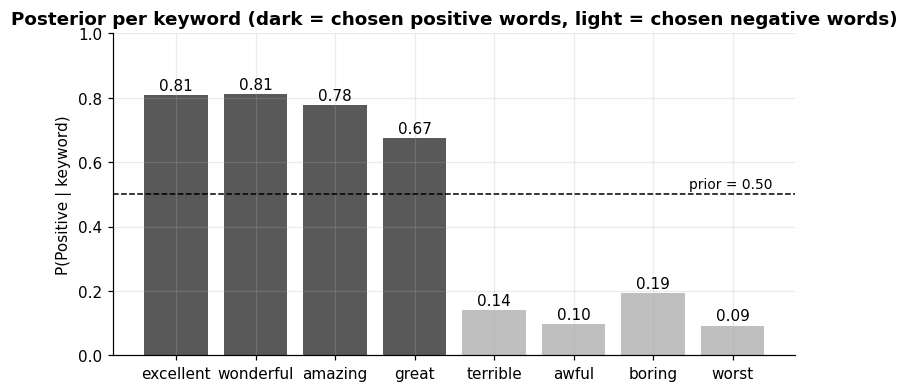

Strongest positive signal: wonderful (0.81).  Weakest positive signal: great (0.67, appears in 25% of reviews).
Strongest negative signal: worst (only 9% of reviews containing it are positive).
All positive keywords above the prior: True | all negative keywords below the prior: True


In [12]:
pl.plot_posteriors(KEYWORDS, [r[4] for r in rows], prior=rows[0][1], n_pos=len(POSITIVE), path=f"{FIG}/bayes_posteriors.png"); plt.show()

best_pos = max(rows[:len(POSITIVE)], key=lambda r: r[4]); weak_pos = min(rows[:len(POSITIVE)], key=lambda r: r[4])
best_neg = min(rows[len(POSITIVE):], key=lambda r: r[4])
print(f"Strongest positive signal: {best_pos[0]} ({best_pos[4]:.2f}).  Weakest positive signal: {weak_pos[0]} "
      f"({weak_pos[4]:.2f}, appears in {weak_pos[3]:.0%} of reviews).")
print(f"Strongest negative signal: {best_neg[0]} (only {best_neg[4]:.0%} of reviews containing it are positive).")
print("All positive keywords above the prior:", all(r[4] > r[1] for r in rows[:len(POSITIVE)]),
      "| all negative keywords below the prior:", all(r[4] < r[1] for r in rows[len(POSITIVE):]))

**Limits to mention.** A keyword is counted once per review (presence, not frequency). Negation is ignored ("not great" still counts as *great*). Each keyword is evaluated on its own, so nothing here assumes independence between words.

---
# Part 3: Gradient descent, manual calculation

Done by hand. The derivation (chain rule for $\partial J/\partial m$ and $\partial J/\partial b$), the three updates (one each by Milliam, Dedine and Cedric) and the trend are in [`docs/Part3_Manual_Calculations.pdf`](docs/Part3_Manual_Calculations.pdf) and are walked through in the presentation. Part 4 below turns the same calculation into code.

---
# Part 4: Gradient descent in code with SciPy

### Setup

Same problem as the handwritten Part 3: $\hat y = Xm + b$ with the given $X$, $y$, $m_0=[-1,2]$, $b_0=[1,1]$ and the MSE cost. $b$ is a vector with one entry per data point, so every operation is a matrix operation. The brief gives no learning rate, so we use $\alpha=0.01$ (gradient descent is stable only below about 0.0157 for this data). Three updates, one per member.

In [13]:
N_MEMBERS = 3
OWNERS = ["Milliam", "Dedine", "Cedric"]       # who performed each hand-calculated update
LR = 0.01
X  = np.array([[1., 3.], [4., 10.]])
y  = np.array([5., 6.])
m0 = np.array([-1., 2.])
b0 = np.array([1., 1.])

### 4.1 A function that takes an equation and returns its derivative

`gd.partial_derivative(f, theta, i)` accepts any equation `f` of a parameter vector and uses `scipy.differentiate.derivative` to compute $\partial f/\partial\theta_i$. `gd.scipy_gradient` stacks one derivative per parameter. First a check on a function whose derivative we know, $f(x,y)=x^3+2xy^2$:

In [14]:
f = lambda t: t[0] ** 3 + 2 * t[0] * t[1] ** 2
theta = np.array([2.0, 3.0])
print("SciPy gradient :", np.round(gd.scipy_gradient(f, theta), 6))
print("Exact gradient :", [3 * 2**2 + 2 * 3**2, 4 * 2 * 3], " (3x^2 + 2y^2, 4xy)")

SciPy gradient : [30. 24.]
Exact gradient : [30, 24]  (3x^2 + 2y^2, 4xy)


Now the same check on our MSE cost against the chain-rule formula from Part 3:

In [15]:
g_scipy = gd.scipy_gradient(lambda t: gd.cost_of_theta(t, X, y), gd.pack(m0, b0))
dm_a, db_a = gd.analytic_gradients(X, m0, b0, y)
print("SciPy    [dJ/dm, dJ/db]:", np.round(g_scipy, 6))
print("Analytic [dJ/dm, dJ/db]:", np.round(np.concatenate([dm_a, db_a]), 6))
assert np.allclose(g_scipy, np.concatenate([dm_a, db_a]), atol=1e-6)

SciPy    [dJ/dm, dJ/db]: [ 45. 113.   1.  11.]
Analytic [dJ/dm, dJ/db]: [ 45. 113.   1.  11.]


### 4.2 Every step visible

The loop below spells out each quantity: predictions, error, cost, the matrix product $X^\top u$, the SciPy gradient, and the updates. It runs for three updates so the numbers can be compared with the hand calculations. With $n=2$ the factor $2/n$ equals 1, so $X^\top u$ and $\partial J/\partial m$ print the same numbers.

In [16]:
m, b = m0.copy(), b0.copy()
for t in range(1, N_MEMBERS + 1):
    y_hat = X @ m + b                                   # predictions
    u = y_hat - y                                       # error
    cost = u @ u / len(y)                               # MSE
    Xt_u = X.T @ u                                      # matrix product used by dJ/dm
    grad = gd.scipy_gradient(lambda th: gd.cost_of_theta(th, X, y), gd.pack(m, b))   # SciPy derivatives
    dm, db = grad[:2], grad[2:]
    m_new, b_new = m - LR * dm, b - LR * db             # updates
    print(f"Update {t} ({OWNERS[t - 1]})")
    print(f"  y_hat = {np.round(y_hat, 4)}   u = {np.round(u, 4)}   J = {cost:.4f}")
    print(f"  X^T u = {np.round(Xt_u, 4)}   dJ/dm = (2/n) X^T u = {np.round(dm, 4)}   dJ/db = (2/n) u = {np.round(db, 4)}")
    print(f"  m: {np.round(m, 4)} -> {np.round(m_new, 4)}     b: {np.round(b, 4)} -> {np.round(b_new, 4)}")
    m, b = m_new, b_new

Update 1 (Milliam)
  y_hat = [ 6. 17.]   u = [ 1. 11.]   J = 61.0000
  X^T u = [ 45. 113.]   dJ/dm = (2/n) X^T u = [ 45. 113.]   dJ/db = (2/n) u = [ 1. 11.]
  m: [-1.  2.] -> [-1.45  0.87]     b: [1. 1.] -> [0.99 0.89]
Update 2 (Dedine)
  y_hat = [2.15 3.79]   u = [-2.85 -2.21]   J = 6.5033
  X^T u = [-11.69 -30.65]   dJ/dm = (2/n) X^T u = [-11.69 -30.65]   dJ/db = (2/n) u = [-2.85 -2.21]
  m: [-1.45  0.87] -> [-1.3331  1.1765]     b: [0.99 0.89] -> [1.0185 0.9121]
Update 3 (Cedric)
  y_hat = [3.2149 7.3447]   u = [-1.7851  1.3447]   J = 2.4974
  X^T u = [3.5937 8.0917]   dJ/dm = (2/n) X^T u = [3.5937 8.0917]   dJ/db = (2/n) u = [-1.7851  1.3447]
  m: [-1.3331  1.1765] -> [-1.369   1.0956]     b: [1.0185 0.9121] -> [1.0364 0.8987]


### 4.3 Run to near convergence and plot

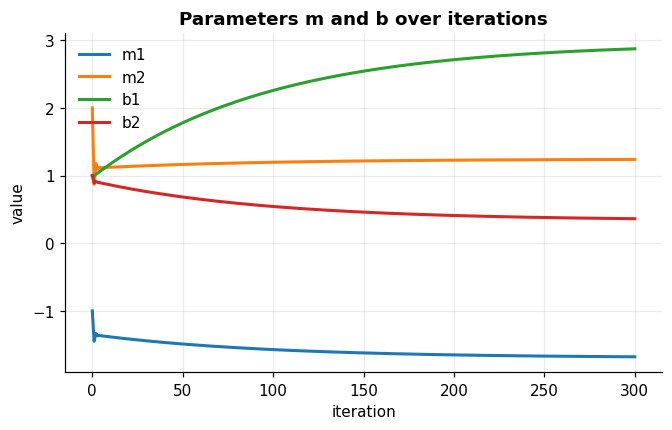

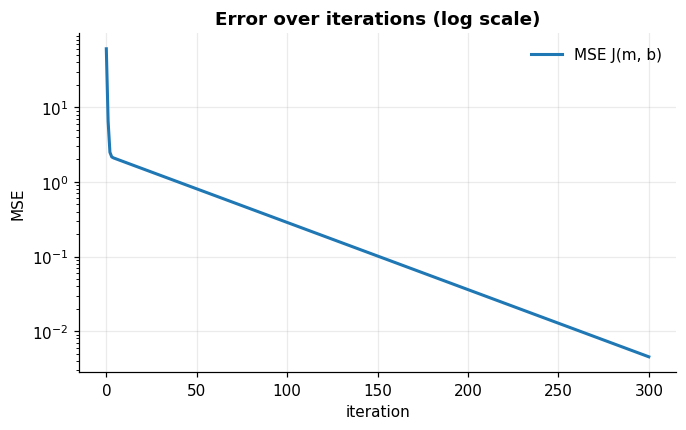

In [17]:
N_ITER = 300
m_fin, b_fin, hist = gd.run_gradient_descent(X, y, m0, b0, LR, N_ITER)
its, M, B, J = gd.history_arrays(hist)

pl.plot_lines(its, {"m1": M[:, 0], "m2": M[:, 1], "b1": B[:, 0], "b2": B[:, 1]},
              "Parameters m and b over iterations", "iteration", "value", path=f"{FIG}/gd_parameters.png"); plt.show()
pl.plot_lines(its, {"MSE J(m, b)": J}, "Error over iterations (log scale)", "iteration", "MSE",
              path=f"{FIG}/gd_error.png", logy=True); plt.show()

The same two plots over the first 20 iterations, with the three hand-calculated updates marked, show the large early steps:

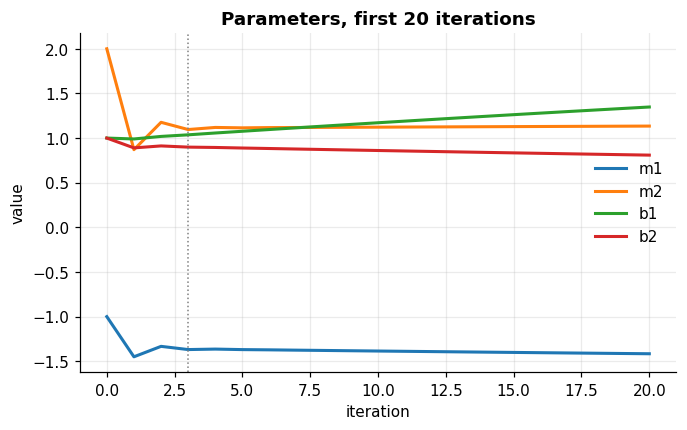

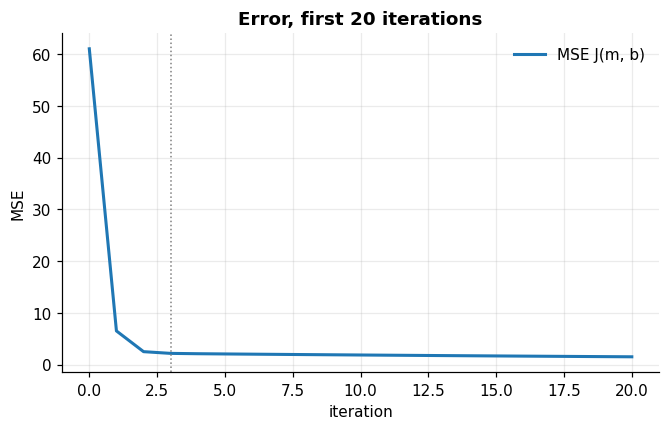

In [18]:
k = 21
pl.plot_lines(its[:k], {"m1": M[:k, 0], "m2": M[:k, 1], "b1": B[:k, 0], "b2": B[:k, 1]},
              "Parameters, first 20 iterations", "iteration", "value", vlines={"update 3": N_MEMBERS}); plt.show()
pl.plot_lines(its[:k], {"MSE J(m, b)": J[:k]}, "Error, first 20 iterations", "iteration", "MSE",
              vlines={"update 3": N_MEMBERS}); plt.show()

### 4.4 Predictions with the final m and b

final m = [-1.6794  1.2382]    final b = [2.8734 0.3618]
MSE: 61.0 at the start, 2.1645 after the 3 hand-calculated updates, 0.004522 after 300 iterations


,x,y (true),y_hat (final),error
0,"(1.0, 3.0)",5.0000,4.9087,-0.0913
1,"(4.0, 10.0)",6.0000,6.0268,0.0268


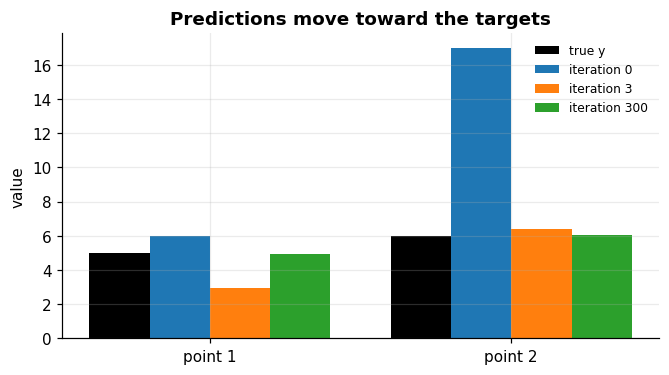

In [19]:
y_pred = gd.predict(X, m_fin, b_fin)
print("final m =", np.round(m_fin, 4), "   final b =", np.round(b_fin, 4))
print(f"MSE: {J[0]:.1f} at the start, {J[3]:.4f} after the 3 hand-calculated updates, {J[-1]:.6f} after {N_ITER} iterations")
display(pd.DataFrame({"x": [tuple(row) for row in X], "y (true)": y, "y_hat (final)": y_pred, "error": y_pred - y}))
pl.plot_predictions(y, [(f"iteration {t}", hist[t]["y_hat"]) for t in (0, 3, len(hist) - 1)]); plt.show()

**Reading the result.** The error keeps falling toward zero. The parameters do not settle on unique values: $[X\;I]$ has rank 2 but there are 4 unknowns (two entries of $m$, two of $b$), so many $(m,b)$ fit the two data points exactly. The values reached depend on the starting point and the learning rate, which is why $b$ keeps drifting while the error is already tiny.